# Sentence-Role Classification in Medical Abstracts

**Goal:** Fine-Tune Biomedical Transformers vs. Classical Machine Learning on PubMed RCT dataset.  
**Dataset:** Real biomedical abstract sentences (PubMed RCT, sentence-level), categorized into 5 labels (`BACKGROUND`, `OBJECTIVE`, `METHODS`, `RESULTS`, `CONCLUSIONS`).

## 1. Data Loading & Pre-processing Setup

First, we load the required libraries, mount Google Drive, and examine the structure of the raw PubMed RCT text files.

In [71]:
# Check the Structure of the dataset
import pandas as pd

filepath = "/content/drive/MyDrive/esi-triage-ml-vs-transformers/pubmed-rct/PubMed_20k_RCT/train.txt"

with open(filepath, 'r') as file:
    for i, line in enumerate(file):
        if i >= 100:
            break
        print(line, end='')

###24293578
OBJECTIVE	To investigate the efficacy of 6 weeks of daily low-dose oral prednisolone in improving pain , mobility , and systemic low-grade inflammation in the short term and whether the effect would be sustained at 12 weeks in older adults with moderate to severe knee osteoarthritis ( OA ) .
METHODS	A total of 125 patients with primary knee OA were randomized 1:1 ; 63 received 7.5 mg/day of prednisolone and 62 received placebo for 6 weeks .
METHODS	Outcome measures included pain reduction and improvement in function scores and systemic inflammation markers .
METHODS	Pain was assessed using the visual analog pain scale ( 0-100 mm ) .
METHODS	Secondary outcome measures included the Western Ontario and McMaster Universities Osteoarthritis Index scores , patient global assessment ( PGA ) of the severity of knee OA , and 6-min walk distance ( 6MWD ) .
METHODS	Serum levels of interleukin 1 ( IL-1 ) , IL-6 , tumor necrosis factor ( TNF ) - , and high-sensitivity C-reactive protein

In [17]:
import pandas as pd

def parse_pubmed_rct(filepath):
    """
    Parses the raw PubMed RCT text file into a structured pandas DataFrame.
    Each entry contains the abstract ID, target label, sentence text, line number,
    total lines, and character length of the sentence.
    """
    parsed_data = []
    with open(filepath, 'r') as file:
        lines = file.readlines()

    current_abstract = []
    abstract_id = ""
    for line in lines:
        line = line.strip()
        if line.startswith("###"):
            abstract_id = line.replace("###", "")
            current_abstract = []
        elif line == "":
            total_lines = len(current_abstract)
            for i, (label, text) in enumerate(current_abstract):
                parsed_data.append({
                    'abstract_id': abstract_id,
                    'label': label,
                    'text': text,
                    'line_number': i,
                    'total_lines': total_lines,
                    'line_length': len(text)
                })
        else:
            parts = line.split('\t', 1)
            if len(parts) == 2:
                current_abstract.append((parts[0], parts[1]))

    return pd.DataFrame(parsed_data)

# Load and parse the dataset
df_parsed = parse_pubmed_rct(filepath)
display(df_parsed.head(10))
print(f"Parsed Dataset Shape: {df_parsed.shape}")

,abstract_id,label,text,line_number,total_lines,line_length
0,24293578,OBJECTIVE,To investigate the efficacy of 6 weeks of dail...,0,12,282
1,24293578,METHODS,A total of 125 patients with primary knee OA w...,1,12,143
2,24293578,METHODS,Outcome measures included pain reduction and i...,2,12,111
3,24293578,METHODS,Pain was assessed using the visual analog pain...,3,12,67
4,24293578,METHODS,Secondary outcome measures included the Wester...,4,12,209
5,24293578,METHODS,"Serum levels of interleukin 1 ( IL-1 ) , IL-6 ...",5,12,147
6,24293578,RESULTS,There was a clinically relevant reduction in t...,6,12,161
7,24293578,RESULTS,The mean difference between treatment arms ( 9...,7,12,208
8,24293578,RESULTS,"Further , there was a clinically relevant redu...",8,12,180
9,24293578,RESULTS,These differences remained significant at 12 w...,9,12,52



Parsed Dataset Shape: (180040, 6)


## 2. Feature Engineering & Dataset Creation

In this step, we enrich our dataset by computing useful textual metrics, such as the relative position of a sentence within its abstract, and flags indicating numeric content presence.

In [19]:
# Calculate the normalized relative position within the abstract
df_parsed['relative_position'] = df_parsed['line_number'] / df_parsed['total_lines']
df_parsed['contains_numeric'] = df_parsed['text'].str.contains(r'\d|%', regex=True)

print("Dataset enrichment completed.")
display(df_parsed.head(5))

,abstract_id,label,text,line_number,total_lines,line_length,relative_position
0,24293578,OBJECTIVE,To investigate the efficacy of 6 weeks of dail...,0,12,282,0.000000
1,24293578,METHODS,A total of 125 patients with primary knee OA w...,1,12,143,0.083333
2,24293578,METHODS,Outcome measures included pain reduction and i...,2,12,111,0.166667
3,24293578,METHODS,Pain was assessed using the visual analog pain...,3,12,67,0.250000
4,24293578,METHODS,Secondary outcome measures included the Wester...,4,12,209,0.333333
5,24293578,METHODS,"Serum levels of interleukin 1 ( IL-1 ) , IL-6 ...",5,12,147,0.416667
6,24293578,RESULTS,There was a clinically relevant reduction in t...,6,12,161,0.500000
7,24293578,RESULTS,The mean difference between treatment arms ( 9...,7,12,208,0.583333
8,24293578,RESULTS,"Further , there was a clinically relevant redu...",8,12,180,0.666667
9,24293578,RESULTS,These differences remained significant at 12 w...,9,12,52,0.750000


## 3. Exploratory Data Analysis (EDA)

We utilize Seaborn to uncover hidden structures in our abstract classes, exploring overall distributions, positional sequence structures, sentence lengths, and alphanumeric content distribution.

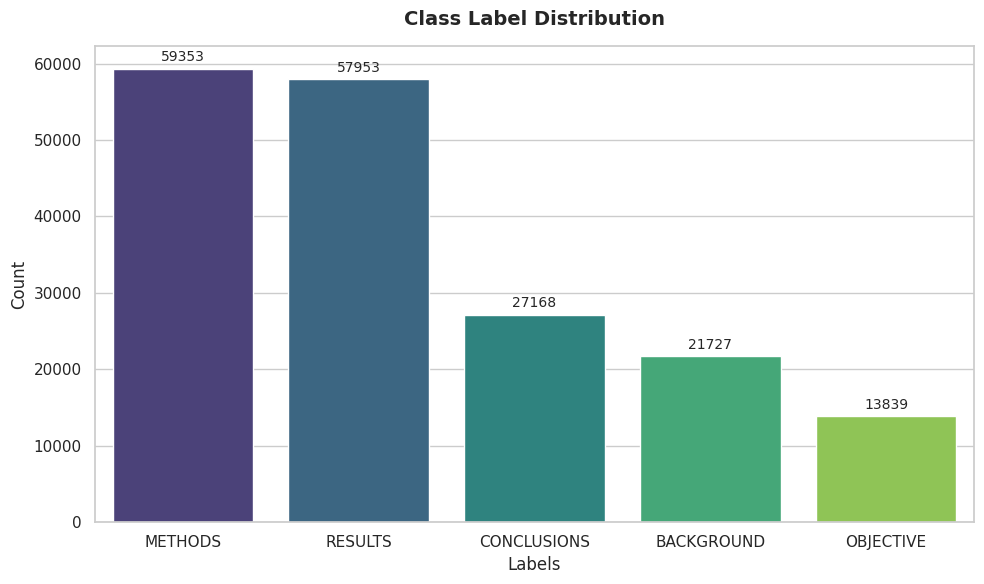

In [68]:
import matplotlib.pyplot as plt
import seaborn as sns

labels = df_parsed['label'].value_counts()
plt.figure(figsize=(10, 6))
sns.set_theme(style='whitegrid')

ax = sns.barplot(x=labels.index, y=labels.values, hue=labels.index, palette='viridis', legend=False)

# Add exact count labels on top of the bars
for container in ax.containers:
    ax.bar_label(container, fmt='%d', label_type='edge', padding=3, fontsize=10)

plt.title("Class Label Distribution", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Labels", fontsize=12)
plt.ylabel("Count", fontsize=12)
plt.tight_layout()
plt.show()

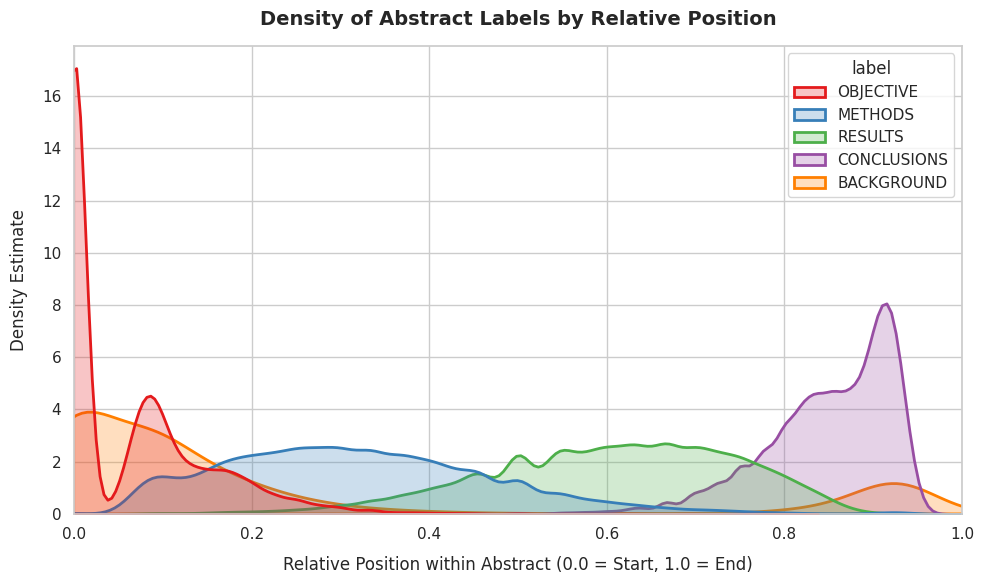

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

plt.figure(figsize=(10, 6))
sns.kdeplot(
    data=df_parsed,
    x='relative_position',
    hue='label',
    common_norm=False,
    fill=True,
    palette='Set1',
    alpha=0.25,
    linewidth=2
)

plt.title("Density of Abstract Labels by Relative Position", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Relative Position within Abstract (0.0 = Start, 1.0 = End)", fontsize=12, labelpad=10)
plt.ylabel("Density Estimate", fontsize=12, labelpad=10)
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

### 2. Abstract Length Distribution
This histogram shows how many sentences make up typical abstracts across our parsed dataset.

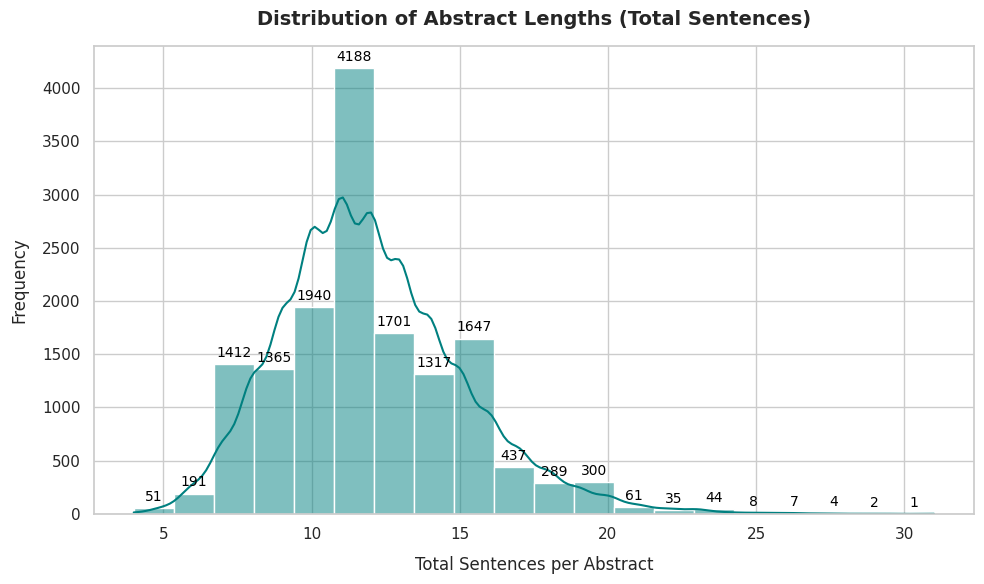

In [59]:
import pandas as pd

# Group by abstract_id to extract unique lengths per abstract
unique_abstracts = df_parsed.drop_duplicates(subset=['abstract_id'])

plt.figure(figsize=(10, 6))
ax = sns.histplot(
    data=unique_abstracts,
    x='total_lines',
    bins=20,
    kde=True,
    color='teal',
    edgecolor='white'
)

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(
            f"{int(height)}",
            (p.get_x() + p.get_width() / 2.0, height),
            ha="center",
            va="center",
            xytext=(0, 8),
            textcoords="offset points",
            fontsize=10,
            color="black",
        )

plt.title("Distribution of Abstract Lengths (Total Sentences)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Total Sentences per Abstract", fontsize=12, labelpad=10)
plt.ylabel("Frequency", fontsize=12, labelpad=10)
plt.tight_layout()
plt.show()

### 3. Numeric Content Share by Label
This plot measures what percentage of sentences in each class contain digits or a percentage sign (`%`), indicating how data-rich the sentence is.

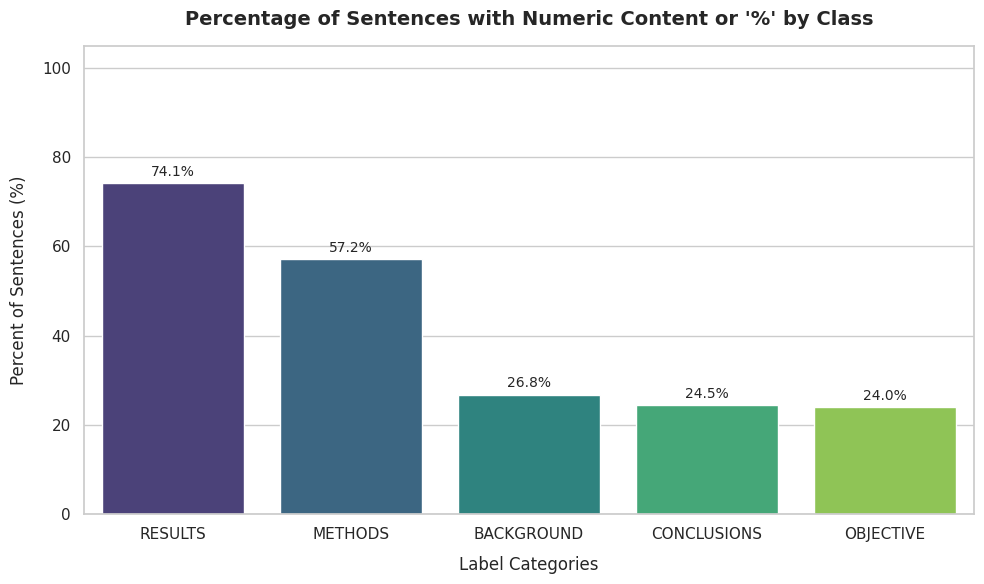

In [49]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate percent per class label
numeric_shares = df_parsed.groupby('label')['contains_numeric'].mean().reset_index()
numeric_shares['percentage'] = numeric_shares['contains_numeric'] * 100

plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=numeric_shares.sort_values(by='percentage', ascending=False),
    x='label',
    y='percentage',
    hue='label',
    palette='viridis',
    dodge=False,
    legend=False
)

# Add percentage labels on top of the bars
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', label_type='edge', padding=3, fontsize=10)

plt.title("Percentage of Sentences with Numeric Content or '%' by Class", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Label Categories", fontsize=12, labelpad=10)
plt.ylabel("Percent of Sentences (%)", fontsize=12, labelpad=10)
plt.ylim(0, 105)
plt.tight_layout()
plt.show()

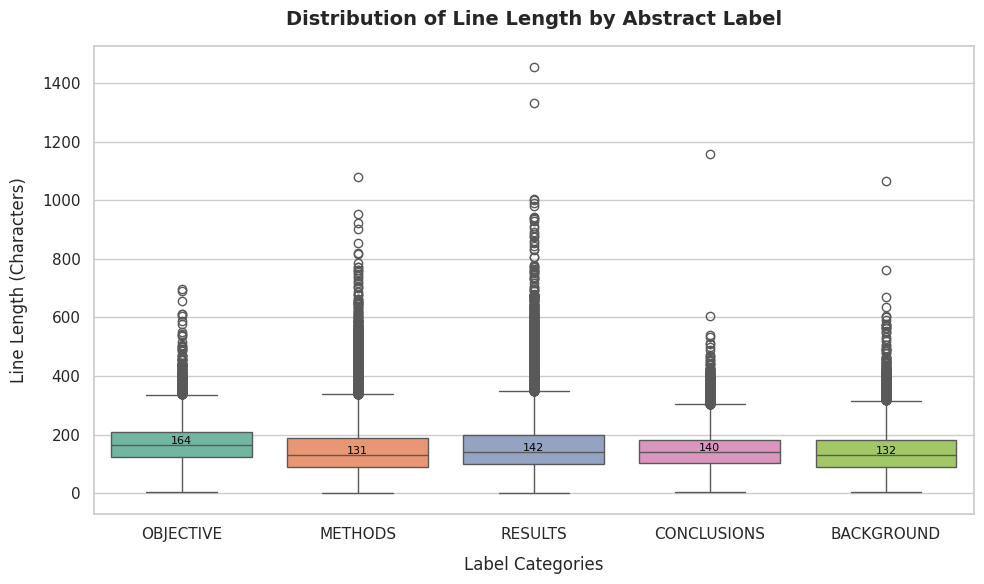

In [66]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_theme(style='whitegrid')
plt.figure(figsize=(10, 6))

ax = sns.boxplot(
    data=df_parsed,
    x='label',
    y='line_length',
    hue='label',
    palette='Set2',
    legend=False,
)

box_medians = df_parsed.groupby(['label'])['line_length'].median()
for i, label in enumerate(df_parsed['label'].unique()):
    median_val = box_medians[label]
    ax.text(i, median_val + 3, f"{int(median_val)}",
            horizontalalignment='center', size=8, color='black')

plt.title(
    "Distribution of Line Length by Abstract Label",
    fontsize=14,
    fontweight="bold",
    pad=15
)
plt.xlabel("Label Categories", fontsize=12, labelpad=10)
plt.ylabel("Line Length (Characters)", fontsize=12, labelpad=10)
plt.tight_layout()
plt.show()